## The link of the dataset is:
https://www.cita.utoronto.ca/~xuduo/downloads_3body/sampling_0/

In [1]:
import h5py
f = h5py.File("./dataset/results_batch_00_sampling_0.hdf5", "r")
f.visit(print)
f.close()


APs_complete
LANs_complete
angMomentum_complete
aratios_complete
eccs_complete
energy_complete
incs_complete
masses_complete
mratios_complete
periods_complete
positions_complete
smaxes_complete
tAnos_complete
times_complete
velocities_complete


In [16]:
path = "./dataset/results_batch_00_sampling_0.hdf5"
with h5py.File(path, "r") as f:
    def show(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(f"[DATASET] {name} shape={obj.shape} dtype={obj.dtype}")
        else:
            print(f"[GROUP  ] {name}")
    f.visititems(show)

[DATASET] APs_complete shape=(8000, 1001, 2) dtype=float64
[DATASET] LANs_complete shape=(8000, 1001, 2) dtype=float64
[DATASET] angMomentum_complete shape=(8000, 1001, 3) dtype=float64
[DATASET] aratios_complete shape=(8000, 1001, 1) dtype=float64
[DATASET] eccs_complete shape=(8000, 1001, 2) dtype=float64
[DATASET] energy_complete shape=(8000, 1001, 1) dtype=float64
[DATASET] incs_complete shape=(8000, 1001, 2) dtype=float64
[DATASET] masses_complete shape=(8000, 1001, 3) dtype=float64
[DATASET] mratios_complete shape=(8000, 1001, 2) dtype=float64
[DATASET] periods_complete shape=(8000, 1001, 2) dtype=float64
[DATASET] positions_complete shape=(8000, 1001, 3, 3) dtype=float64
[DATASET] smaxes_complete shape=(8000, 1001, 2) dtype=float64
[DATASET] tAnos_complete shape=(8000, 1001, 2) dtype=float64
[DATASET] times_complete shape=(8000, 1001) dtype=float64
[DATASET] velocities_complete shape=(8000, 1001, 3, 3) dtype=float64


In [19]:
import h5py
import numpy as np

KEYS = [
    "APs_complete","LANs_complete","angMomentum_complete","aratios_complete",
    "eccs_complete","energy_complete","incs_complete","masses_complete",
    "mratios_complete","periods_complete","positions_complete",
    "smaxes_complete","tAnos_complete","times_complete","velocities_complete"
]

def load_one_h5(path, T=None, dtype=np.float32):
    sl = slice(None) if T is None else slice(0, T)
    out = {}
    with h5py.File(path, "r") as f:
        for k in KEYS:
            if k == "times_complete":
                out[k] = f[k][:, sl].astype(dtype)              # (N,T)
            else:
                # 其它都是 (N,T,...) 或 (N,T,3,3)
                out[k] = f[k][:, sl, ...].astype(dtype)
    return out

paths = [
    "./dataset/results_batch_00_sampling_0.hdf5",
    "./dataset/results_batch_01_sampling_0.hdf5",
    "./dataset/results_batch_02_sampling_0.hdf5",
    "./dataset/results_batch_03_sampling_0.hdf5",
    "./dataset/results_batch_04_sampling_0.hdf5",
]

# optional: limit to first T steps for faster loading and prototyping
T = 100

dicts = [load_one_h5(p, T=T) for p in paths]

data = {k: np.concatenate([d[k] for d in dicts], axis=0) for k in KEYS}

print(data["positions_complete"].shape)  # (N_total, T, 3, 3)



(40000, 100, 3, 3)


In [20]:
# check if we get the same data as before
N = 8000*5  # 5 files, each with 5000 systems
assert data["positions_complete"].shape == (N, T, 3, 3)
assert data["velocities_complete"].shape == (N, T, 3, 3)
assert data["times_complete"].shape == (N, T)


In [ ]:
import pandas as pd
import torch

df = pd.read_csv("dataset/completed_systems_sampling_0.txt", sep=r"\s+", header=None,
                 names=["index","num_batch","time_unbound","ignore_other_than-1","diagnosis"])

# datatype
df = df.astype({"index":"int64","num_batch":"int64","time_unbound":"float32","ignore_other_than-1":"float32","dignosis":"int64"})

arr = df.to_numpy()
print(df.columns)
print(arr.shape, arr.dtype)
print(arr[:10, :5])  
tensor = torch.from_numpy(arr)  
print(tensor.shape, tensor.dtype)


Index(['index', 'num_batch', 'time_unbound', 'ignore_other_than-1',
       'dignosis'],
      dtype='str')
(40000, 5) float64
[[360.           0.          10.           1.2236681    0.        ]
 [179.           0.           5.           1.22473073   0.        ]
 [183.           0.           5.           1.24002266   0.        ]
 [361.           0.          20.           1.27451062   0.        ]
 [178.           0.          30.           1.24214554   0.        ]
 [349.           0.          15.           1.26477361   0.        ]
 [180.           0.          20.           1.25246263   0.        ]
 [176.           0.          20.           1.27163601   0.        ]
 [367.           0.          65.           1.30586576   0.        ]
 [182.           0.          30.           1.32230663   0.        ]]
torch.Size([40000, 5]) torch.float64


## Dataset Summary: Triple-System Integrations for ML

This document summarizes the dataset structure and the physical parameters used as inputs for our machine learning model.

---

## 1) Data Structure & Manifest

### Files
- **`ICs_sampling_0.hdf5`**  
  Initial conditions (**ICs**) for **5,000 unique system configurations**.

- **`results_batch_0x_sampling_0.hdf5`** (Batches **0–4**)  
  Time-series integration outputs covering **40,000 total integrations**.  
  - Each of the **5,000** configurations has **8 variations** → 5,000 × 8 = 40,000 runs.

- **`completed_systems_sampling_0.txt`**  
  “Source of truth” list for **valid / completed runs**.

### Crucial Validity Rule
- If **Column 4 = `-1`**, **ignore that system** — the integration did **not** complete successfully.

---

## 2) ML Input Features (11 Independent Parameters)

We treat **11 independent parameters** from the **ICs file** as our primary ML features (static input vector per configuration).

### Feature List
1. **Semimajor Axis Ratio (1)**
   - $( a_{\text{in}} / a_{\text{out}} )$

2. **Mass Ratios (2)**
   - Inner: $( m_1 / m_2 )$  
   - Outer: $( m_3 / (m_1 + m_2))$

3. **Eccentricities (2)**
   - Orbital elongation (inner + outer)

4. **Inclinations $i$\)$ (2)**
   - Vertical tilt of the orbital planes (inner + outer)

5. **Arguments of Periapsis $\omega$(2)**
   - Orientation of the ellipse within the orbital plane (inner + outer)

6. **Longitudes of Ascending Node $\Omega$ (2)**
   - Horizontal “twist” / rotation of the orbital plane (inner + outer)

✅ Total: **1 + 2 + 2 + 2 + 2 + 2 = 11 parameters**

---

## 3) Understanding the Time-Series Outputs

Each results file contains a time-series dimension of length **1,001**, representing the system’s evolution:

- **Index `0`**: starting state  
- **Index `1000`**: state after **5,000 initial outer orbits**

### Mapping Index → Physical Time
To convert an index to timestamps, use the dataset:

- **`times_complete`** (in the results files)

---

## 4) Robustness & Chaos Testing Built into the Dataset

To ensure the model generalizes and captures chaotic sensitivity, the dataset includes:

### A) Phase Variations (“tAnos”)
- Each system is simulated under **4 different starting phases**, including **0° and 180° shifts**.
- Since orbital phases evolve continuously, we **exclude phase variables** from the initial static ML feature vector.

### B) Sensitivity / Chaos Perturbations
- Some systems include a **tiny perturbation in semimajor axis**, creating nearly identical initial conditions.
- This supports a classic **chaos test**: do nearby trajectories diverge over time?

---

## 5) Background Reference & Visuals

### Physics Reference (Orbital Angles)
For a deeper explanation of the orbital angles and conventions, see:

- Section 2 of the paper:  
  https://arxiv.org/pdf/2207.03151

### Provided Visuals
- GIFs illustrating: $i$, $\omega$, and $\Omega$
- Example dynamics: **stable vs. unstable** triple systems

---

## Notes
- In the hdf5 files, the naming convention is as follows:
    - aratios: Semimajor Axis Ratio
    - mratios: Mass Ratios
    - eccs: Eccentricities
    - incs: Inclinations
    - APs: Arguments of Periapsis
    - LANs: Longitudes of Ascending Node
    - tAnos: True anomalies (orbit phases)
- The columns in the txt file:
    - column 1 (index of system)
    - column 2 (time in units of initial outer orbit period that the system says bound; 5000 is max since that is how long I ran it)
    - column 3 (the batch in which the system is written)
    - column 4 (ignore other than -1)
    - column 5 (ignore;diagnostics)
- Explanation of index of system: every 8 indices (e.g., 0 to 7) is
one unique system with the phase and 'chaos' differences Duo
mentions. Also, an index 2000 in results batch 04 hdf5 file
corresponds to index 2000+4*8000 = 34000 in the IC hdf5 file.

- In the hdf5 files, the naming convention is as follows:
    - aratios: Semimajor Axis Ratio
    - mratios: Mass Ratios
    - eccs: Eccentricities
    - incs: Inclinations
    - APs: Arguments of Periapsis
    - LANs: Longitudes of Ascending Node
    - tAnos: True anomalies (orbit phases)
- The columns in the txt file:
column 1 (index of system), column 2 (time in units of initial outer
orbit period that the system says bound; 5000 is max since that is
how long I ran it), column 3 (the batch in which the system is
written), column 4 (ignore other than -1), column 5 (ignore;
diagnostics)
>>
- Explanation of index of system: every 8 indices (e.g., 0 to 7) is
one unique system with the phase and 'chaos' differences Duo
mentions. Also, an index 2000 in results batch 04 hdf5 file
corresponds to index 2000+4*8000 = 34000 in the IC hdf5 file.

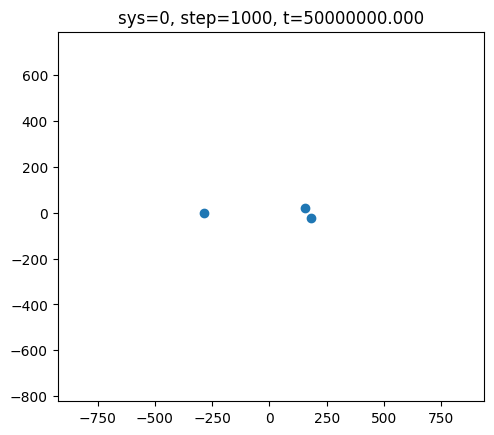

In [14]:
import h5py
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

path = "./dataset/results_batch_00_sampling_0.hdf5"
sys_id = 0

with h5py.File(path, "r") as f:
    pos = f["positions_complete"][sys_id]  # (1001,3,3)
    t   = f["times_complete"][sys_id]      # (1001,)

fig, ax = plt.subplots()
sc = ax.scatter(pos[0,:,0], pos[0,:,1])


pad = 0.05
xmin, xmax = pos[:,:,0].min(), pos[:,:,0].max()
ymin, ymax = pos[:,:,1].min(), pos[:,:,1].max()
dx, dy = xmax-xmin, ymax-ymin
ax.set_xlim(xmin - pad*dx, xmax + pad*dx)
ax.set_ylim(ymin - pad*dy, ymax + pad*dy)
ax.set_aspect("equal", "box")
title = ax.set_title("")

def update(frame):
    sc.set_offsets(pos[frame,:,0:2])  # 3x2
    title.set_text(f"sys={sys_id}, step={frame}, t={t[frame]:.3f}")
    return sc, title

frames = range(0, pos.shape[0], 5) 
ani = FuncAnimation(fig, update, frames=frames, interval=20, blit=True)
plt.rcParams["animation.html"] = "html5"
HTML(ani.to_jshtml())


## Possible insteresting readings:
1. SPEOCK: https://github.com/dtamayo/spock
2. SPOCK2.0: https://arxiv.org/abs/2501.15017
3. A Bayesian neural network predicts the dissolution of compact planetary systems：https://arxiv.org/abs/2101.04117
4. iTransformer: https://github.com/thuml/iTransformer
5. PatchTST：https://github.com/PatchTST/PatchTST

## How to create more data around the boundary to the discriminative model more robust 
###  Build an initial “base” dataset by simulation

1. Sample the 11-D parameters from a chosen prior (your baseline sampling policy).
2. Convert these parameters into full orbital initial conditions and run a high-fidelity N-body integration up to a fixed maximum time.
3. Assign labels:
   - **Bound** if the system remains bound up to the maximum integration time,
   - **Unbound** if it becomes unbound earlier (based on your ejection/disruption criteria).

This yields an initial labeled dataset spanning the global parameter space.



###  Actively enrich the dataset with critical (near-boundary) samples

To concentrate compute on the most informative systems:

1. Train a preliminary classifier (preferably an ensemble) on the base dataset.
2. Use an acquisition rule to select the next batch of parameters likely to lie near the transition
3. Integrate these newly selected systems with the same high-fidelity simulator and add their true labels.
4. Repeat for several rounds.

This iteratively sharpens coverage of the **bound/unbound boundary** while maintaining broad coverage via baseline sampling.


### Generative modeling to densify the boundary (diffusion / flows)

After collecting a set of validated near-boundary samples:

- Train a conditional generative model on the parameter vectors (often a normalizing flow is simplest in low dimensions; diffusion is also possible).
- Condition on a continuous proxy when available (e.g., disruption time  or a binned risk score), then generate additional near-boundary candidates.
- Validate generated candidates with the high-fidelity integrator and keep only correctly labeled samples.



## Several possible ways to improve the model
### 1) Reframe the Problem as "Survival Analysis" Instead of Regression 

Your current label is `t ∈ [0,5000]`, where `t=5000` likely means "reached the limit without unbinding." This is called **right censoring**.

### How to do it (Deep Cox / Discrete-time Hazard)

- **Model Output**: The model outputs the **hazard** (the probability of unbinding in that segment) for each time segment.
- **Training Objective**: Use the log-likelihood for survival analysis:
  - For actual unbind samples: Encourage high hazard near the correct time.
  - For censored samples (`t=5000`): Encourage low hazard previously, but do not force it to say it *will* unbind.

### Why this is an "underexplored direction"

In ML for N-body stability, many people directly perform classification (stable/unstable) or regress a specific time. However, treating it **strictly as survival / censored regression**, especially combined with deep sequence encoders, is rarer and "statistically more correct."

### What you gain

- More reasonable handling of samples like "`t=5000`" → **Prediction is no longer artificially flattened by the 5000 cap.**
- You can also output:
  - Expected bound time
  - Quantiles (10%, 50%, 90%)
  - Uncertainty (especially useful for boundary systems)

---

### 2) Use "Distributional Prediction" Instead of Point Prediction: Predict $p(t \mid x)$ 

The error in bound time is usually not Gaussian; it is often heavy-tailed or even multi-modal (due to different mechanisms).

Two effective approaches:

### A) Mixture Density Network (MDN)

Output parameters for a mixture of distributions (e.g., $K=3\sim8$) to let the model learn "which mechanism leads to which timescale."

### B) Quantile Regression

Directly predict $t_{0.1}, t_{0.5}, t_{0.9}$. This is more stable for "boundary systems" and allows you to define "risk intervals."

**Novelty Point**: Emphasizing "time distribution + risk intervals" on N-body bound time instead of a single number usually looks more like a research contribution than standard regression.

---

### 3) Mechanism Decomposition: MoE + Survival Analysis 

Turn the hazard model from (1) into an MoE:

- **Gating**: Decide which expert to use based on the early evolution of orbital elements (or proxies you construct: AMD, a-ratio, m-ratio, energy drift, ecc growth rate...).
- **Experts**: Each expert outputs a set of hazard curves (corresponding to the timescale of a specific instability mechanism).

You can produce very strong plots:

- Expert A covers high $e$ / close encounter proxies → Hazard is high early on.
- Expert B covers resonance proxies → Hazard rises in the mid-to-late stage.
- Expert C covers slow diffusion → Hazard is flat but accumulates over the long term.

**This is no longer just "using MoE"**; it is "using MoE to explicitly decompose dynamic mechanisms + time-to-event modeling adapted for censored data."

---

### 4) "Invariant/Slow Variable" Representation Learning: Learn a representation insensitive to phase but sensitive to mechanism (Very physics-oriented innovation)

Your input is a sequence of orbital elements, which contains many "phase/angle" variables that make learning difficult for the network (APs, LANs, etc.).

### A very new and practical direction

First, perform **Self-Supervised Pre-training** to learn "slow variable representations":

- **Goal**: Given different time windows of the same system, the embedding should be consistent (insensitive to phase changes).
- **Differentiation**: But it must be separable for different systems (sensitive to mechanism/stability).

Implementation can be simple:

- Contrastive (SimCLR/TS2Vec ideas) or masked prediction.
- Add a physical regularization: Encourage the embedding to correlate with slow drifts (Energy, Angular Momentum, AMD).

Then perform (1) survival / (2) distribution prediction on this embedding.

**Novelty**: This is "self-supervised representation designed for N-body," which looks more like a research direction than direct supervised learning.

---

### 5) The Diffusion you mentioned earlier: Use it for a "Boundary Sample Generation + Survival Model Calibration" Loop 

Few people do this closed loop, so it sounds very novel:

1. Train a survival/distribution model first.
2. Use **uncertainty** (gating entropy, expert disagreement, quantile interval width) to identify "boundary" regions.
3. Use diffusion to generate initial conditions in these regions (as you already know how).
4. Iteratively train with the new samples (Active Learning).